## LUMA - Lokalny Urok Mistrzostwa Artystycznego

LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, gości (miejscowi i turyści), promocje i sezonowość

In [3]:
# import bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# ustawienie ziarna RNG
RNG_SEED = 20261018
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20261018


In [5]:
# zdefiniowanie stałych
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
KATEGORIE = ["Ceramika", "Tekstylia", "Biżuteria", "Scrapbooking", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

## Przygotowanie danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne

In [6]:
catalog = pd.DataFrame({
    "kategoria": KATEGORIE,
    "popyt_lok_base": [120, 180, 130, 80, 160, 150, 70, 50, 110], # śr. popyt lokalny,
    "popyt_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 90], # śr. popyt turystyczny
    "cena_pln_base": [85, 120, 150, 230, 40, 35, 250, 215, 135] # śr. cena jednostkowa
})

Wyliczony typowy przychód tygodniowy (lokalni + turyści) * cena

In [13]:
catalog["przychod_typowy_pln"] = (catalog["popyt_lok_base"] + catalog["popyt_tur_base"]) * catalog["cena_pln_base"]
catalog

,kategoria,popyt_lok_base,popyt_tur_base,cena_pln_base,przychod_typowy_pln
0,Ceramika,120,60,85,15300
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Scrapbooking,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,50,40,215,19350
8,Alkohole,110,90,135,27000


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%).

In [15]:
def losuj_popyt(catalog, rng, wariancja=0.15, boost_lok=0.9, boost_tur=0.0):
    df = catalog[["kategoria", "popyt_lok_base", "popyt_tur_base"]].copy()

    eps_l = np.clip(rng.normal(loc=1.0, scale=wariancja, size=len(df)), 0.5, 1.8)
    eps_t = np.clip(rng.normal(loc=1.0, scale=wariancja, size=len(df)), 0.5, 1.8)
    df["popyt_lok"] = (df["popyt_lok_base"] * (1 + boost_lok)) * eps_l
    df["popyt_tur"] = (df["popyt_tur_base"] * (1 + boost_tur)) * eps_t

    df["popyt_lok"] = np.maximum(df["popyt_lok"].round().astype(int), 0)
    df["popyt_tur"] = np.maximum(df["popyt_tur"].round().astype(int), 0)

    return df[["kategoria", "popyt_lok", "popyt_tur"]]

Wyliczenie przychodu lokalnego, turystycznego i łącznego

In [14]:
def policz_przychody(popyt_df, catalog):
    df = popyt_df.merge(catalog[["kategoria", "cena_pln_base"]], on="kategoria", how="left")
    df["przych_lok"] = df["popyt_lok"] * df["cena_pln_base"]
    df["przych_tur"] = df["popyt_tur"] * df["cena_pln_base"]
    df["przych_total"] = df["przych_lok"] + df["przych_tur"]
    return df[["kategoria", "przych_lok", "przych_tur", "przych_total"]]

Generowanie danych tygodniowych

In [17]:
def wygeneruj_tydzien(catalog, rng, wariancja=0.15, boost_lok=0.0, boost_tur=0.0):
    popyty = losuj_popyt(catalog, rng, wariancja, boost_lok, boost_tur)
    return policz_przychody(popyty, catalog)

### Wygenerowanie i analiza danych tygodniowych

In [18]:
t1 = wygeneruj_tydzien(catalog, rng)
t1.merge(catalog[["kategoria", "cena_pln_base"]], on="kategoria", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Suma przychodów w tygodniu 1 (PLN): ", int(t1["przych_total"].sum()))

Tydzień 1 - przychody per kategoria (PLN)


,kategoria,przych_lok,przych_tur,przych_total
0,Ceramika,12835,6120,18955
1,Tekstylia,22200,3960,26160
2,Biżuteria,26850,10650,37500
3,Scrapbooking,20010,8970,28980
4,Przetwory,6200,3200,9400
5,Dekoracje,5705,1155,6860
6,Stolarka,17250,12250,29500
7,Masarstwo,10750,9890,20640
8,Alkohole,11610,11070,22680


Suma przychodów w tygodniu 1 (PLN):  200675


Podstawowy wykres

<Axes: xlabel='kategoria'>

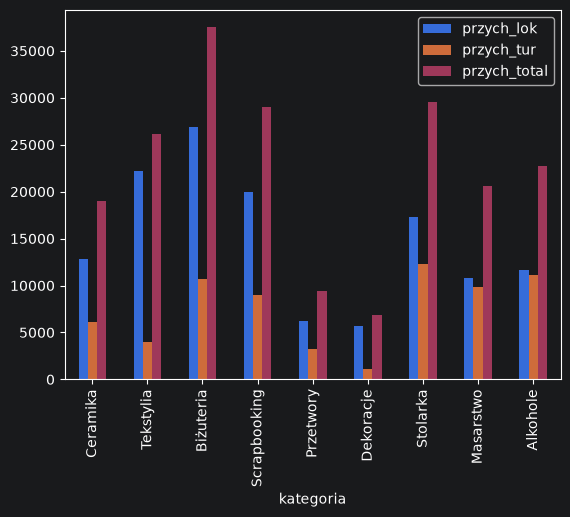

In [25]:
t1.plot.bar(x="kategoria", rot=90)

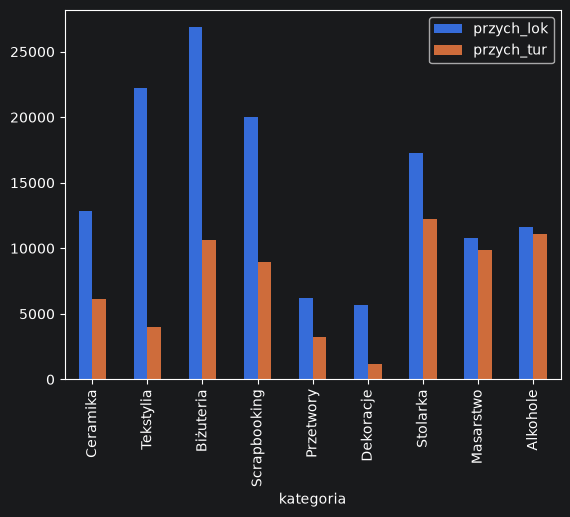

In [27]:
t1.plot.bar(x="kategoria", y=["przych_lok", "przych_tur"], rot=90)
plt.show()